# Turtle Breakout 11 — one account across 30 coins: risk-allocation rules R0–R4, long only and long + reverse

Pre-registration: `discussions/Turtle_Breakout/013_claude_tb11_preregistration.md`. Code: `src/data_engineering/modeling/turtle_portfolio.py`.

All 30 coins share **one** account (equity marked daily at 17:00 New York). Base risk per trade $r = 2\%\cdot\mathrm{HWM}$.
R0 no rule · R1 heat cap $H$ · R2 correlation scaling · R3 cluster caps $C$ (K = 4) · R4 walk-forward coin weights.
**Discovery** 2020–2023 chooses $H$ and $C$ (max Calmar). **Evaluation** 2024-01-01 → end decides: Calmar(rule) − Calmar(R0m), R0m = R0 at the same mean open risk; block bootstrap, Holm over 6 (R1–R3 × 2 variants).

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB11_SYNTHETIC=1`.

In [1]:
import os, sys, json, gc, time, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 150)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_sizing as ts, turtle_reverse as tr, turtle_portfolio as tp

SYNTHETIC = os.getenv('TB11_SYNTHETIC', '0') == '1'
P = tb.Params(); PP = tp.PParams(); RP = tr.RParams()
DISC0, DISC1 = tp.DISC; EVAL0 = tp.EVAL_START
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb11-')) / '11'; PP = tp.PParams(n_boot=300, H_grid=(0.04, 0.08, 0.15), C_grid=(0.02, 0.06))
    DISC0, DISC1, EVAL0 = pd.Timestamp('2021-07-01', tz='UTC'), pd.Timestamp('2023-07-01', tz='UTC'), pd.Timestamp('2023-07-01', tz='UTC')
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '11'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_portfolio.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print(json.dumps(tp.registration(PP), indent=1, default=str))

OK
{
 "f": 0.02,
 "stop_atr": 2.0,
 "pos_cap": 3.0,
 "start_equity": 100000.0,
 "H_grid": [
  0.04,
  0.06,
  0.08,
  0.1,
  0.15,
  0.2,
  0.3
 ],
 "C_grid": [
  0.02,
  0.04,
  0.06,
  0.08
 ],
 "K": 4,
 "min_take": 0.25,
 "corr_win": 60,
 "corr_min": 30,
 "corr_fallback": 0.7,
 "clus_win": 90,
 "clus_min": 60,
 "r4_min_trades": 10,
 "r4_max": 3.0,
 "block_days": 21,
 "n_boot": 2000,
 "alpha": 0.05,
 "seed": 20261101,
 "status": "PREREGISTERED_TB013",
 "version": "TB11-0.1.0",
 "rules": [
  "R0",
  "R1",
  "R2",
  "R3",
  "R4"
 ],
 "discovery": [
  "2020-01-01 00:00:00+00:00",
  "2024-01-01 00:00:00+00:00"
 ],
 "evaluation_start": "2024-01-01 00:00:00+00:00",
 "selection": "H (R1) and C (R3) maximise Calmar on DISCOVERY, per variant; ties -> smaller value",
 "decision": "EVALUATION: Calmar(rule) - Calmar(R0m) for R1, R2, R3 x {long, long_rev}; R0m = R0 with f scaled to the rule's mean open risk in the window (same exposure, no rule); paired 21-day block bootstrap, one-sided p, Holm o

## 1. Books: trades of every coin, long only and long + reverse

In [2]:
BOOKS = {'long': {}, 'long_rev': {}}; COV = []
if SYNTHETIC:
    BOOKS['long'] = tp.synthetic_books(10, 1100, seed=3, with_reverse=False)
    BOOKS['long_rev'] = tp.synthetic_books(10, 1100, seed=3, with_reverse=True)
    COV = pd.DataFrame([{'asset': a, 'longs': len(b.trades), 'reverses': int((BOOKS['long_rev'][a].trades.kind == 'reverse').sum())} for a, b in BOOKS['long'].items()])
else:
    for a in tf.UNIVERSE:
        t1 = time.time()
        pu = DATA / f'{a}USDT_um_1m.parquet'
        if not pu.exists():
            print(a, 'missing'); continue
        b, _ = tf.load_um(pu)
        fpth = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fpth)) if fpth.exists() else None
        if a == 'TON':
            b = b[b.index < tr.TON_CUTOFF]
        D = tb.prepare_asset(a, b, f, P)
        start = b.index[0] + pd.Timedelta(days=30)
        L0 = ts.trade_list(D, P, start, RP, with_reverse=False); L1 = ts.trade_list(D, P, start, RP, with_reverse=True)
        BOOKS['long'][a] = tp.make_book(D, L0, P); BOOKS['long_rev'][a] = tp.make_book(D, L1, P)
        COV.append({'asset': a, 'start': start, 'end': b.index[-1], 'longs': len(L0), 'reverses': int((L1.kind == 'reverse').sum()), 'funding': f is not None})
        print(f'{a}: {len(L0)} longs, {COV[-1]["reverses"]} reverses, {time.time() - t1:.0f}s')
        del b, D; gc.collect()
    COV = pd.DataFrame(COV)
display(COV)
RET = tp.returns_panel(BOOKS['long'])
LAST = max(b.trades.t_out.max() for b in BOOKS['long'].values())
print('returns panel', RET.shape, '| last trade exit', LAST)

BTC: 54 longs, 33 reverses, 4s
ETH: 50 longs, 25 reverses, 3s
SOL: 46 longs, 26 reverses, 2s
XRP: 47 longs, 30 reverses, 2s
BNB: 55 longs, 32 reverses, 2s
DOGE: 44 longs, 25 reverses, 2s
ADA: 51 longs, 37 reverses, 3s
LINK: 58 longs, 39 reverses, 3s
DOT: 45 longs, 32 reverses, 2s
LTC: 54 longs, 40 reverses, 3s
BCH: 52 longs, 36 reverses, 2s
UNI: 46 longs, 31 reverses, 2s
NEAR: 44 longs, 27 reverses, 2s
APT: 32 longs, 25 reverses, 1s
ARB: 26 longs, 17 reverses, 1s
OP: 34 longs, 24 reverses, 1s
SUI: 28 longs, 17 reverses, 1s
FIL: 41 longs, 28 reverses, 1s
ATOM: 52 longs, 36 reverses, 1s
ETC: 50 longs, 37 reverses, 1s
INJ: 35 longs, 22 reverses, 1s
AAVE: 52 longs, 37 reverses, 1s
TON: 38 longs, 34 reverses, 1s
WIF: 19 longs, 11 reverses, 1s
HBAR: 33 longs, 25 reverses, 1s
XLM: 53 longs, 36 reverses, 1s
SEI: 22 longs, 13 reverses, 1s
TIA: 25 longs, 18 reverses, 1s
ENA: 20 longs, 13 reverses, 0s
WLD: 26 longs, 17 reverses, 1s


,asset,start,end,longs,reverses,funding
0,BTC,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,54,33,True
1,ETH,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,50,25,True
2,SOL,2020-10-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,46,26,True
3,XRP,2020-02-05 08:25:00+00:00,2026-10-24 00:00:00+00:00,47,30,True
4,BNB,2020-03-11 08:05:00+00:00,2026-10-24 00:00:00+00:00,55,32,True
5,DOGE,2020-08-09 09:05:00+00:00,2026-10-24 00:00:00+00:00,44,25,True
6,ADA,2020-03-01 08:05:00+00:00,2026-10-24 00:00:00+00:00,51,37,True
7,LINK,2020-02-16 08:05:00+00:00,2026-10-24 00:00:00+00:00,58,39,True
8,DOT,2020-09-21 07:05:00+00:00,2026-10-24 00:00:00+00:00,45,32,True
9,LTC,2020-02-08 08:10:00+00:00,2026-10-24 00:00:00+00:00,54,40,True


returns panel (2489, 30) | last trade exit 2026-10-24 00:00:00+00:00


## 2. Discovery (2020–2023): grids for H (R1) and C (R3); every rule

In [3]:
def run(variant, rule, t0, t1, pp=PP, books=None, **kw):
    o = tp.simulate(books or BOOKS[variant], rule, pp, t0, t1, R=RET, **kw)
    Dd = tp.daily_curve(o['equity'], pp.start_equity)
    return {**tp.metrics(Dd, pp.start_equity), 'max_open_risk': o['max_open_risk'], 'mean_open_risk': o['mean_open_risk'],
            'max_gross_lev': o['max_gross_lev'], **o['stats']}, Dd, o
T0 = time.time(); DISC_ROWS = []; SEL = {}
for v in ('long', 'long_rev'):
    for rule, kw in [('R0', {}), ('R2', {}), ('R4', {})] + [('R1', {'H': h}) for h in PP.H_grid] + [('R3', {'C': c}) for c in PP.C_grid]:
        m, _, _ = run(v, rule, DISC0, DISC1, **kw)
        DISC_ROWS.append({'variant': v, 'rule': rule, 'H': kw.get('H', np.nan), 'C': kw.get('C', np.nan), **m})
    print(v, f'{time.time() - T0:.0f}s')
DISC = pd.DataFrame(DISC_ROWS)
for v in ('long', 'long_rev'):
    g = DISC[DISC.variant == v]
    SEL[v] = {'H': tp.select(g[g.rule == 'R1'], 'H'), 'C': tp.select(g[g.rule == 'R3'], 'C')}
print('selected:', SEL)
display(DISC[['variant', 'rule', 'H', 'C', 'cagr', 'max_dd', 'calmar', 'sharpe', 'ruined', 'max_open_risk', 'mean_open_risk', 'max_gross_lev', 'entries', 'skipped', 'scaled']].round(3))

long 35s
long_rev 88s
selected: {'long': {'H': 0.2, 'C': 0.08}, 'long_rev': {'H': 0.3, 'C': 0.04}}


,variant,rule,H,C,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped,scaled
0,long,R0,NaN,NaN,-1.000,-1.000,-1.000,0.624,True,0.380,0.051,28.503,266,0,0
1,long,R2,NaN,NaN,0.904,-0.496,1.822,1.566,False,0.105,0.033,1.709,580,0,552
2,long,R4,NaN,NaN,-1.000,-1.000,-1.000,0.795,True,0.357,0.054,26.799,285,5,0
3,long,R1,0.04,NaN,0.503,-0.396,1.272,1.240,False,0.040,0.024,1.163,118,462,24
4,long,R1,0.06,NaN,0.954,-0.382,2.499,1.550,False,0.060,0.034,1.327,174,406,59
5,long,R1,0.08,NaN,1.462,-0.416,3.515,1.783,False,0.080,0.044,1.638,215,365,65
6,long,R1,0.10,NaN,1.868,-0.687,2.720,1.701,False,0.100,0.052,3.073,258,322,44
7,long,R1,0.15,NaN,2.776,-0.871,3.188,1.667,False,0.150,0.070,8.390,360,220,59
8,long,R1,0.20,NaN,3.907,-0.953,4.098,1.733,False,0.200,0.084,17.500,427,153,22
9,long,R1,0.30,NaN,-1.000,-1.000,-1.000,0.689,True,0.300,0.050,70.934,256,10,3


## 3. Evaluation (2024 → end): decision

In [4]:
EV_ROWS, EV_CURVES, EV_OUT, TESTS = [], {}, {}, []
for v in ('long', 'long_rev'):
    for rule, kw in (('R0', {}), ('R1', {'H': SEL[v]['H']}), ('R2', {}), ('R3', {'C': SEL[v]['C']}), ('R4', {})):
        m, Dd, o = run(v, rule, EVAL0, None, **kw)
        EV_ROWS.append({'variant': v, 'rule': rule, 'param': kw.get('H', kw.get('C', np.nan)), **m}); EV_CURVES[(v, rule)] = Dd; EV_OUT[(v, rule)] = o
    r0 = EV_OUT[(v, 'R0')]['mean_open_risk']
    for rule in ('R1', 'R2', 'R3'):
        fm = PP.f * EV_OUT[(v, rule)]['mean_open_risk'] / r0
        m, Dd, o = run(v, 'R0', EVAL0, None, pp=replace(PP, f=fm))
        EV_ROWS.append({'variant': v, 'rule': f'R0m_for_{rule}', 'param': fm, **m}); EV_CURVES[(v, f'R0m_{rule}')] = Dd
        t = tp.calmar_diff(EV_CURVES[(v, rule)], Dd, PP, PP.seed + len(TESTS))
        t0 = tp.calmar_diff(EV_CURVES[(v, rule)], EV_CURVES[(v, 'R0')], PP, PP.seed + 100 + len(TESTS))
        TESTS.append({'variant': v, 'rule': rule, 'f_R0m': fm, **t, 'vs_R0_calmar_diff': t0['calmar_diff'], 'vs_R0_lo95': t0['lo95'], 'vs_R0_hi95': t0['hi95'], 'vs_R0_p': t0['p']})
EVAL = pd.DataFrame(EV_ROWS); TESTS = pd.DataFrame(TESTS)
TESTS['p_holm'] = tp.holm(TESTS.p.to_numpy())
TESTS['result'] = np.where(TESTS.p_holm < PP.alpha, 'IMPROVES', 'NO_DIFFERENCE')
display(EVAL[['variant', 'rule', 'param', 'cagr', 'max_dd', 'calmar', 'sharpe', 'ruined', 'max_open_risk', 'mean_open_risk', 'max_gross_lev', 'entries', 'skipped', 'scaled']].round(3))
display(TESTS.round(4))
DEC = {'selected': SEL, 'tests': TESTS[['variant', 'rule', 'calmar_diff', 'lo95', 'hi95', 'p', 'p_holm', 'result']].to_dict('records'),
       'any_improves': bool((TESTS.result == 'IMPROVES').any())}
DEC['verdict'] = 'RULE_IMPROVES: ' + ', '.join(f"{r.rule}/{r.variant}" for r in TESTS.itertuples() if r.result == 'IMPROVES') if DEC['any_improves'] else 'NO_RULE_BEATS_SAME_EXPOSURE'
print(json.dumps(DEC, indent=1, default=float))

,variant,rule,param,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped,scaled
0,long,R0,NaN,-1.000,-1.000,-1.000,-0.180,True,0.451,0.029,93.901,136,0,0
1,long,R1,0.200,-1.000,-1.000,-1.000,-0.082,True,0.200,0.063,130.649,272,192,16
2,long,R2,NaN,0.140,-0.522,0.268,0.515,False,0.133,0.035,2.234,652,0,629
3,long,R3,0.080,-1.000,-1.000,-1.000,-0.379,True,0.180,0.048,69.877,216,261,13
4,long,R4,NaN,-1.000,-1.000,-1.000,0.372,True,0.467,0.031,251.922,125,11,0
5,long,R0m_for_R1,0.044,-1.000,-1.000,-1.000,-0.464,True,0.911,0.030,103.379,80,0,0
6,long,R0m_for_R2,0.024,-1.000,-1.000,-1.000,-0.144,True,0.526,0.029,27.447,130,0,0
7,long,R0m_for_R3,0.033,-1.000,-1.000,-1.000,0.521,True,0.699,0.036,154.909,107,0,0
8,long_rev,R0,NaN,-1.000,-1.000,-1.000,0.295,True,0.600,0.116,2672.639,443,0,0
9,long_rev,R1,0.300,-1.000,-1.000,-1.000,0.439,True,0.300,0.142,5871.847,535,175,31


,variant,rule,f_R0m,calmar_diff,lo95,hi95,p,vs_R0_calmar_diff,vs_R0_lo95,vs_R0_hi95,vs_R0_p,p_holm,result
0,long,R1,0.0435,0.0000,-3.1730,3.0152,0.5225,0.0000,-1.9249,2.3910,0.5172,1.0000,NO_DIFFERENCE
1,long,R2,0.0241,1.2610,-0.0874,4.1322,0.0315,1.2610,-0.5702,3.7438,0.0775,0.1889,NO_DIFFERENCE
2,long,R3,0.0327,-0.0000,-2.2038,1.6183,0.5082,0.0000,-1.8390,1.7512,0.5247,1.0000,NO_DIFFERENCE
3,long_rev,R1,0.0244,0.0000,-2.4056,6.0919,0.5042,0.0000,-2.1300,5.8286,0.4763,1.0000,NO_DIFFERENCE
4,long_rev,R2,0.0125,-0.9157,-27.6231,0.6183,0.7081,1.3855,-1.0556,3.8477,0.0945,1.0000,NO_DIFFERENCE
5,long_rev,R3,0.0128,-0.7750,-40.8333,1.3301,0.6642,1.5127,-0.9690,6.4528,0.0975,1.0000,NO_DIFFERENCE


{
 "selected": {
  "long": {
   "H": 0.2,
   "C": 0.08
  },
  "long_rev": {
   "H": 0.3,
   "C": 0.04
  }
 },
 "tests": [
  {
   "variant": "long",
   "rule": "R1",
   "calmar_diff": 1.3266213683138517e-09,
   "lo95": -3.1730108601963063,
   "hi95": 3.015247721119957,
   "p": 0.5225,
   "p_holm": 1.0,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long",
   "rule": "R2",
   "calmar_diff": 1.2609610561924407,
   "lo95": -0.08741811727182308,
   "hi95": 4.1321896649284735,
   "p": 0.031484257871064465,
   "p_holm": 0.1889055472263868,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long",
   "rule": "R3",
   "calmar_diff": -9.413203594377251e-08,
   "lo95": -2.2038386349479215,
   "hi95": 1.6183476136314068,
   "p": 0.5082458770614693,
   "p_holm": 1.0,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long_rev",
   "rule": "R1",
   "calmar_diff": 2.0665288213983501e-07,
   "lo95": -2.4055917281819177,
   "hi95": 6.091942007138998,
   "p": 0.504247876061969,
   "p_holm": 1.

## 4. Reported: long + reverse vs long under each rule, equal-weight sleeves, full period, 4-coin portfolio

In [5]:
rows = []
for rule in ('R0', 'R1', 'R2', 'R3', 'R4'):
    t = tp.calmar_diff(EV_CURVES[('long_rev', rule)], EV_CURVES[('long', rule)], PP, PP.seed + 500)
    rows.append({'rule': rule, 'calmar_long': float(EVAL[(EVAL.variant == 'long') & (EVAL.rule == rule)].calmar.iloc[0]),
                 'calmar_long_rev': float(EVAL[(EVAL.variant == 'long_rev') & (EVAL.rule == rule)].calmar.iloc[0]), **t})
REV = pd.DataFrame(rows); print('Evaluation: long + reverse minus long (Calmar)'); display(REV.round(3))

# equal-weight sleeves: each coin its own account (TB 10 pool), same windows
SLV = []
for v in ('long', 'long_rev'):
    for name, (a0, a1) in (('discovery', (DISC0, DISC1)), ('evaluation', (EVAL0, None))):
        cur = {}
        for a, bk in BOOKS[v].items():
            o = tp.simulate({a: bk}, 'R0', PP, a0, a1)
            if len(o['equity']) > 30 and o['stats']['entries'] > 0:
                cur[a] = tp.daily_curve(o['equity'], PP.start_equity)
        lr = ts.pooled_log_returns(cur); Dd = PP.start_equity * np.exp(lr.cumsum())
        SLV.append({'variant': v, 'window': name, 'coins': len(cur), **tp.metrics(Dd, PP.start_equity)})
        if name == 'evaluation':
            EV_CURVES[(v, 'sleeves')] = Dd
SLV = pd.DataFrame(SLV); print('Equal-weight sleeves'); display(SLV.round(3))

FULL = []
for v in ('long', 'long_rev'):
    for rule, kw in (('R0', {}), ('R1', {'H': SEL[v]['H']}), ('R2', {}), ('R3', {'C': SEL[v]['C']}), ('R4', {})):
        m, _, _ = run(v, rule, DISC0, None, **kw); FULL.append({'variant': v, 'rule': rule, **m})
        if not SYNTHETIC:
            core = {a: BOOKS[v][a] for a in tf.CONFIRM_ASSETS if a in BOOKS[v]}
            m4, _, _ = run(v, rule, tb.COMMON_START, None, books=core, **kw); FULL.append({'variant': v, 'rule': rule + '_4coins', **m4})
FULL = pd.DataFrame(FULL); print('Full period (2020 -> end) and 4-coin portfolio (from 2020-10-15)')
display(FULL[['variant', 'rule', 'cagr', 'max_dd', 'calmar', 'sharpe', 'ruined', 'max_open_risk', 'mean_open_risk', 'max_gross_lev', 'entries', 'skipped']].round(3))

Evaluation: long + reverse minus long (Calmar)


,rule,calmar_long,calmar_long_rev,calmar_diff,lo95,hi95,p
0,R0,-1.000,-1.000,-0.000,-1.897,2.184,0.503
1,R1,-1.000,-1.000,0.000,-2.720,6.347,0.504
2,R2,0.268,0.393,0.125,-1.413,1.497,0.444
3,R3,-1.000,0.520,1.513,-0.044,5.623,0.027
4,R4,-1.000,-1.000,-0.000,-1.618,1.787,0.496


Equal-weight sleeves


,variant,window,coins,cagr,log_growth,max_dd,calmar,sharpe,ruined,final_multiple
0,long,discovery,27,0.081,0.078,-0.075,1.078,1.155,False,1.365
1,long,evaluation,30,0.045,0.044,-0.093,0.478,0.612,False,1.130
2,long_rev,discovery,27,0.084,0.080,-0.050,1.661,1.170,False,1.380
3,long_rev,evaluation,30,0.053,0.051,-0.081,0.651,0.702,False,1.156


Full period (2020 -> end) and 4-coin portfolio (from 2020-10-15)


,variant,rule,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped
0,long,R0,-1.000,-1.000,-1.000,0.478,True,0.380,0.030,28.503,266,0
1,long,R0_4coins,0.705,-0.361,1.955,1.523,False,0.080,0.026,2.236,178,0
2,long,R1,-1.000,-1.000,-1.000,0.966,True,0.200,0.076,130.649,695,349
3,long,R1_4coins,0.705,-0.361,1.955,1.523,False,0.080,0.026,2.236,178,0
4,long,R2,0.533,-0.522,1.020,1.147,False,0.139,0.034,2.235,1232,0
5,long,R2_4coins,0.371,-0.205,1.812,1.458,False,0.051,0.017,1.079,178,0
6,long,R3,-1.000,-1.000,-1.000,0.722,True,0.180,0.058,69.877,530,527
7,long,R3_4coins,0.705,-0.361,1.955,1.523,False,0.080,0.026,2.236,178,0
8,long,R4,-1.000,-1.000,-1.000,0.609,True,0.357,0.032,26.799,285,5
9,long,R4_4coins,0.654,-0.368,1.777,1.469,False,0.085,0.026,2.178,178,0


## 5. Figures

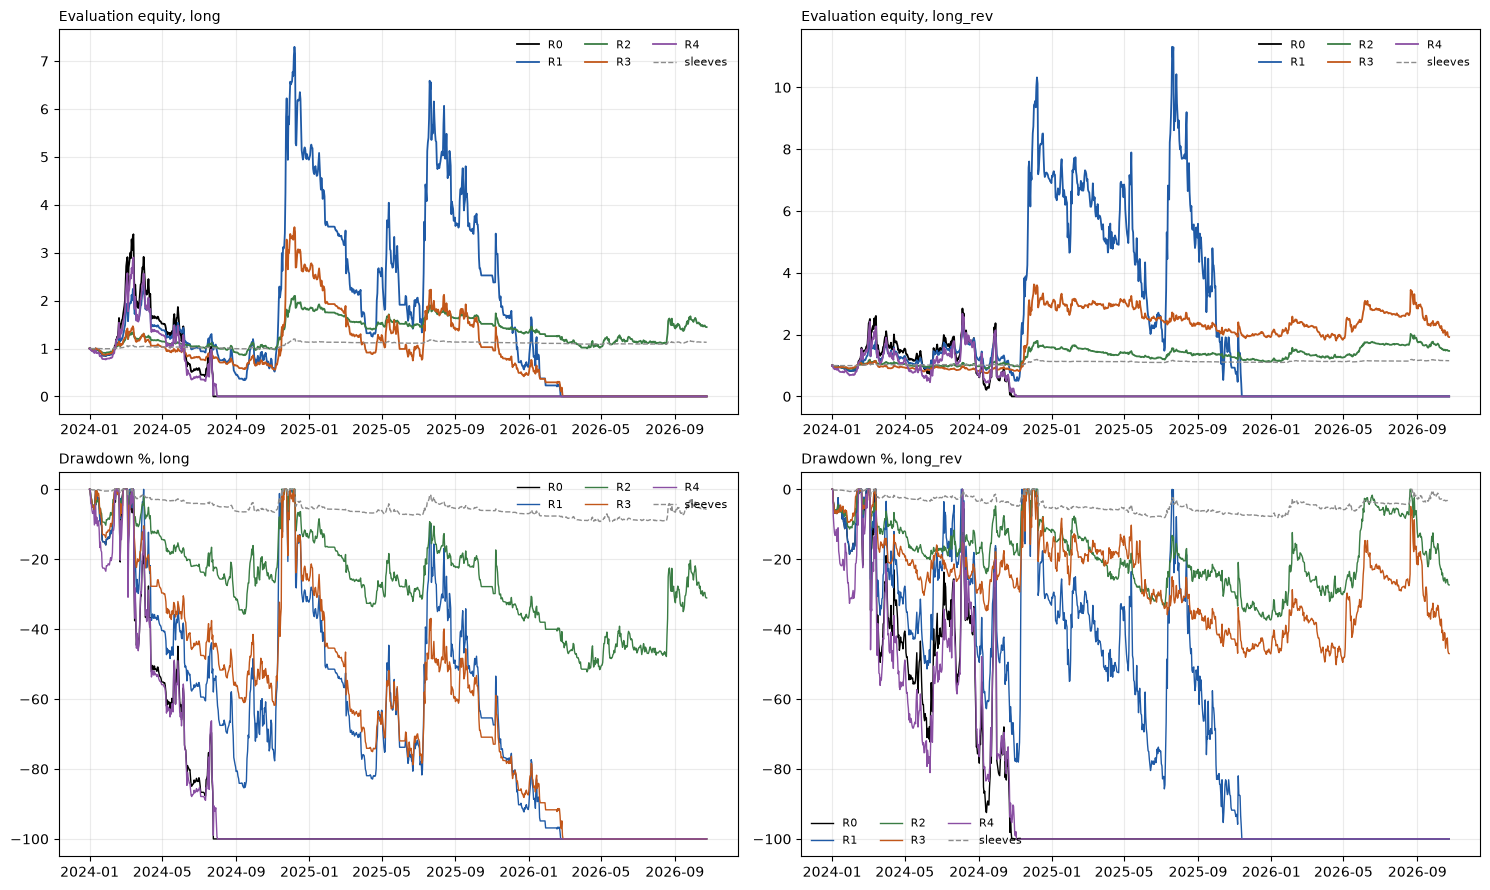

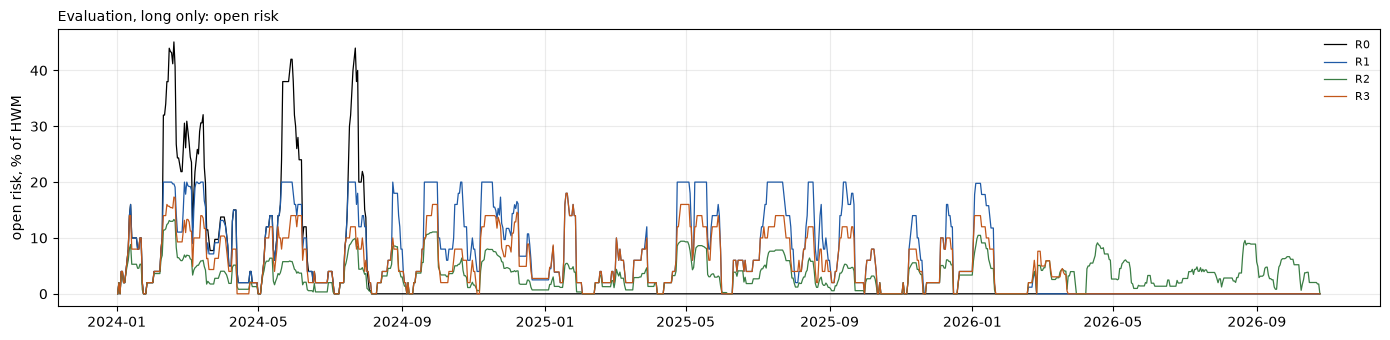

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
colors = {'R0': 'k', 'R1': '#1f5aa6', 'R2': '#3a7d44', 'R3': '#c2571a', 'R4': '#8a4fa3', 'sleeves': '0.55'}
for j, v in enumerate(('long', 'long_rev')):
    for rule in ('R0', 'R1', 'R2', 'R3', 'R4', 'sleeves'):
        c = EV_CURVES[(v, rule)]
        axes[0, j].plot(c.index, c / PP.start_equity, color=colors[rule], lw=1.3 if rule != 'sleeves' else 1.0, ls='-' if rule != 'sleeves' else '--', label=rule)
        axes[1, j].plot(c.index, (c / c.cummax() - 1) * 100, color=colors[rule], lw=1.0, ls='-' if rule != 'sleeves' else '--', label=rule)
    axes[0, j].set_title(f'Evaluation equity, {v}', loc='left', fontsize=10); axes[1, j].set_title(f'Drawdown %, {v}', loc='left', fontsize=10)
    for a in axes[:, j]:
        a.grid(alpha=0.25); a.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
for rule in ('R0', 'R1', 'R2', 'R3'):
    s = EV_OUT[('long', rule)]['open_risk']; ax.plot(s.index, s * 100, color=colors[rule], lw=0.9, label=rule)
ax.set_ylabel('open risk, % of HWM'); ax.set_title('Evaluation, long only: open risk', loc='left', fontsize=10); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
DISC.to_csv(OUT / '11_discovery.csv', index=False); EVAL.to_csv(OUT / '11_evaluation.csv', index=False); TESTS.to_csv(OUT / '11_tests.csv', index=False)
REV.to_csv(OUT / '11_reverse_vs_long.csv', index=False); SLV.to_csv(OUT / '11_sleeves.csv', index=False); FULL.to_csv(OUT / '11_full_and_4coins.csv', index=False)
COV.to_csv(OUT / '11_coverage.csv', index=False)
pd.DataFrame({f'{v}|{r}': c for (v, r), c in EV_CURVES.items()}).to_csv(OUT / '11_eval_curves.csv')
(OUT / '11_decision.json').write_text(json.dumps({'decision': DEC, 'registration': tp.registration(PP), 'synthetic': SYNTHETIC}, indent=1, default=str))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '11_manifest.json').write_text(json.dumps({'version': tp.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'coins': list(BOOKS['long']), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\11
VERDICT: NO_RULE_BEATS_SAME_EXPOSURE
